# EN4554 Assignment 2 — Convolutional Neural Networks

**Name:** Sadaruwan I J M J<br>
**Index number:** 220542J<br>
**GitHub repository:** https://github.com/JeewanthaSadaruwan/EN4554-Assignment2-CNNs

## 1. Setup

Imports, device selection and fixed random seeds so that results are reproducible.

In [1]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.datasets import CIFAR10

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True   # faster convolutions for fixed input sizes

print("PyTorch    :", torch.__version__)
print("torchvision:", torchvision.__version__)
print("Device     :", device, f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")

PyTorch    : 2.11.0+cu128
torchvision: 0.26.0+cu128
Device     : cuda (NVIDIA GeForce RTX 5060 Laptop GPU)


## 1.1 Data: CIFAR-10

CIFAR-10 has 60,000 colour images of size 32×32 in 10 classes (50,000 training and 10,000 test images). It is loaded with `torchvision.datasets.CIFAR10` when the official files are available. Because the official server (cs.toronto.edu) was extremely slow, the identical dataset is otherwise downloaded once from its Hugging Face mirror (`uoft-cs/cifar10`) and cached in `./data`.

As the assignment requires:
- The 50k training images are split into **45k train / 5k validation** with a fixed seed.
- Images are **normalized per channel using statistics of the 45k training split only**.
- The **test set is used only once**, in Task 4.

In [4]:
import io, urllib.request
from PIL import Image

DATA_DIR = "./data"
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
HF_URL = "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/{}-00000-of-00001.parquet"

def load_split(split):
    """Return CIFAR-10 images (N, 32, 32, 3) uint8 and labels (N,). Downloads once, then uses a cache."""
    cache = os.path.join(DATA_DIR, f"cifar10_{split}.npz")
    if os.path.exists(cache):
        d = np.load(cache)
        return d["x"], d["y"]
    # Official files, if they were downloaded by torchvision
    if os.path.isdir(os.path.join(DATA_DIR, "cifar-10-batches-py")):
        ds = CIFAR10(root=DATA_DIR, train=(split == "train"), download=False)
        x, y = ds.data, np.array(ds.targets)
    # Otherwise the Hugging Face mirror (the official server is very slow)
    else:
        os.makedirs(DATA_DIR, exist_ok=True)
        parquet = os.path.join(DATA_DIR, f"cifar10_{split}.parquet")
        if not os.path.exists(parquet):
            print(f"Downloading {split} split ...")
            urllib.request.urlretrieve(HF_URL.format(split), parquet)
        df = pd.read_parquet(parquet)
        x = np.stack([np.array(Image.open(io.BytesIO(b["bytes"])).convert("RGB")) for b in df["img"]])
        y = df["label"].to_numpy()
    np.savez(cache, x=x, y=y)
    return x, y

# Raw images as tensors: uint8 (N, 32, 32, 3) -> float in [0, 1], shape (N, 3, 32, 32)
def to_tensor(x, y):
    return torch.tensor(x).permute(0, 3, 1, 2).float() / 255.0, torch.tensor(y).long()

X_full, y_full = to_tensor(*load_split("train"))
X_test, y_test = to_tensor(*load_split("test"))
assert X_full.shape == (50_000, 3, 32, 32) and X_test.shape == (10_000, 3, 32, 32)

# 45k / 5k train/validation split with a fixed seed
perm = torch.randperm(len(X_full), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45_000], perm[45_000:]
X_train, y_train = X_full[train_idx], y_full[train_idx]
X_val,   y_val   = X_full[val_idx],   y_full[val_idx]

# Per-channel normalization statistics from the training split only
MEAN = X_train.mean(dim=(0, 2, 3))
STD  = X_train.std(dim=(0, 2, 3))

def normalize(x):
    return (x - MEAN.view(1, 3, 1, 1).to(x.device)) / STD.view(1, 3, 1, 1).to(x.device)

print(f"Train: {tuple(X_train.shape)}  Val: {tuple(X_val.shape)}  Test: {tuple(X_test.shape)}")
print("Channel mean:", MEAN.numpy().round(4))
print("Channel std :", STD.numpy().round(4))
print("Train class counts:", torch.bincount(y_train).tolist())
print("Val class counts  :", torch.bincount(y_val).tolist())

Train: (45000, 3, 32, 32)  Val: (5000, 3, 32, 32)  Test: (10000, 3, 32, 32)
Channel mean: [0.4914 0.4821 0.4467]
Channel std : [0.2471 0.2436 0.2617]
Train class counts: [4506, 4519, 4501, 4529, 4483, 4507, 4492, 4500, 4506, 4457]
Val class counts  : [494, 481, 499, 471, 517, 493, 508, 500, 494, 543]


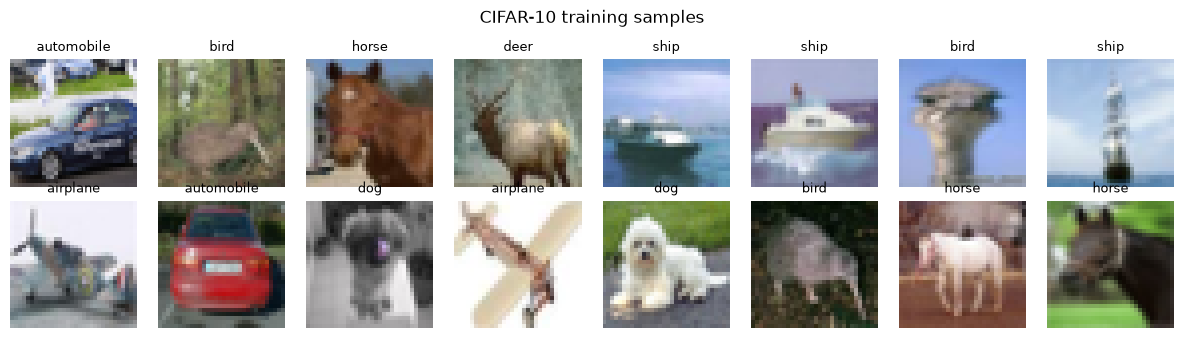

In [5]:
# A few training images with their labels
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).numpy())
    ax.set_title(CLASSES[y_train[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("CIFAR-10 training samples")
plt.tight_layout()
plt.show()

## Task 1: Backpropagation

**(a)** Implement Linear, ReLU, and softmax cross-entropy with explicit forward/backward (no autograd), and assemble an MLP.

#### 1. Linear Layer Implementation (Forward and Backward Pass)

In [ ]:
import torch

torch.manual_seed(42)

class Linear:
    def __init__(self, in_features, out_features):

        self.W = torch.randn(
            in_features, out_features
        ) * (2.0 / in_features) ** 0.5

        self.b = torch.zeros(1, out_features)

    def forward(self, X):
        self.X = X
        Y = X @ self.W + self.b
        return Y

    def backward(self, dY):
        dX = dY @ self.W.T
        self.dW = self.X.T @ dY
        self.db = torch.sum(
            dY, dim=0, keepdim=True
        )
        return dX


#### 2. ReLU Activation Function Implementation (Forward and Backward Pass)

In [4]:

class ReLU:
    def forward(self, X):
        self.X = X
        Y = torch.clamp(X, min=0)
        return Y

    def backward(self, dY):
        dX = dY * (self.X > 0)
        return dX


#### 3. Softmax Cross-Entropy Loss Implementation (Forward and Backward Pass)

In [ ]:
class SoftmaxCrossEntropy:

    def forward(self, logits, labels):
        N = logits.shape[0]

        shifted = logits - logits.max(dim=1, keepdim=True).values
        exp_scores = torch.exp(shifted)

        self.probs = exp_scores / exp_scores.sum(dim=1, keepdim=True)
        self.labels = labels

        log_probs = shifted - torch.log(exp_scores.sum(dim=1, keepdim=True))

        loss = -log_probs[torch.arange(N, device=logits.device), labels].mean()

        return loss

    def backward(self):
        N = self.labels.shape[0]
        dZ = self.probs.clone()
        dZ[torch.arange(N, device=dZ.device), self.labels] -= 1
        dZ = dZ / N

        return dZ


#### 4. Multi-Layer Perceptron (MLP) Assembly and Backpropagation

**MLP Network Architecture** (example: 3 input features, 2 hidden layers with 5 neurons each, 3 output neurons)

- **Input layer:** 3 features, so the input has shape $(N, 3)$.
- **Hidden layer 1:** `Linear(3, 5)` followed by `ReLU`. $W_1$ is $3 \times 5$ and $b_1$ is $1 \times 5$.
- **Hidden layer 2:** `Linear(5, 5)` followed by `ReLU`. $W_2$ is $5 \times 5$ and $b_2$ is $1 \times 5$.
- **Output layer:** `Linear(5, 3)` produces 3 logits (one per class). $W_3$ is $5 \times 3$ and $b_3$ is $1 \times 3$.
- **Loss:** softmax cross-entropy is applied to the logits.
- **Forward pass:** $X \rightarrow$ Linear $\rightarrow$ ReLU $\rightarrow$ Linear $\rightarrow$ ReLU $\rightarrow$ Linear $\rightarrow$ logits $\rightarrow$ loss.
- **Backward pass:** the loss gradient $\partial L / \partial \text{logits}$ is passed through the layers in reverse order. Each layer computes the gradients of its own parameters and returns $\partial L / \partial X$ to the layer before it.
- **Total parameters:** $(3 \cdot 5 + 5) + (5 \cdot 5 + 5) + (5 \cdot 3 + 3) = 20 + 30 + 18 = 68$.

In [8]:

class MLP:
    def __init__(self, input_size, hidden1, hidden2, output_size):
        self.layers = [
            Linear(input_size, hidden1),
            ReLU(),
            Linear(hidden1, hidden2),
            ReLU(),
            Linear(hidden2, output_size)
        ]

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self, dY):
        for layer in reversed(self.layers):
            dY = layer.backward(dY)
        return dY


**(b)** Verify your gradients against autograd and against centred finite differences; report the relative errors. Use `torch.allclose` to check whether the gradients match.


### 1. Manual Gradient Computation and Collection

A small MLP with architecture **3–5–5–3** is initialized using two input samples. Double-precision (`float64`) tensors are used to improve numerical accuracy during gradient verification.

The forward pass computes the softmax cross-entropy loss, while the manually implemented backward pass calculates the gradients using the chain rule.

Finally, the model's weights and biases are stored in `params`, and their corresponding gradients, along with the input gradient, are stored in `manual_grads` for comparison with PyTorch autograd and centred finite differences.


In [23]:

import torch
import torch.nn.functional as F

torch.manual_seed(42)

# Small MLP for gradient checking
model = MLP(3, 5, 5, 3)

# Convert parameters to float64 for accurate numerical checks
for layer in model.layers:
    if isinstance(layer, Linear):
        layer.W = layer.W.double()
        layer.b = layer.b.double()

# Two samples, three input features
X = torch.randn(2, 3, dtype=torch.float64)
labels = torch.tensor([0, 2], dtype=torch.long)

criterion = SoftmaxCrossEntropy()

# Forward pass
logits = model.forward(X)
loss = criterion.forward(logits, labels)

# Manual backward pass
dZ = criterion.backward()
dX = model.backward(dZ)

# Collect parameters and manual gradients
params = {}
manual_grads = {"X": dX.detach().clone()}

for i, layer in enumerate(model.layers):
    if isinstance(layer, Linear):
        params[f"layer{i}.W"] = layer.W
        params[f"layer{i}.b"] = layer.b

        manual_grads[f"layer{i}.W"] = layer.dW.detach().clone()
        manual_grads[f"layer{i}.b"] = layer.db.detach().clone()
print("Manual loss:", loss.item())


Manual loss: 2.451002982173198


In [ ]:
torch.set_printoptions(precision=4, sci_mode=False)

for i, layer in enumerate(model.layers):
    if isinstance(layer, Linear):
        print(f"\n{'='*45}")
        print(f"LINEAR LAYER {i}")
        print(f"{'='*45}")

        print("\nWeight Matrix (W):")
        print(layer.W)

        print("\nWeight Gradient (dL/dW):")
        print(layer.dW)

        print("\nBias Vector (b):")
        print(layer.b)

        print("\nBias Gradient (dL/db):")
        print(layer.db)

print("\nInput Gradient (dL/dX):")
print(dX)


LINEAR LAYER 0

Weight Matrix (W):
tensor([[ 0.2749,  0.1052,  0.1914,  0.1881, -0.9168],
        [-0.1521,  1.8030, -0.5209,  0.3769,  0.2183],
        [ 0.4367,  0.6608,  0.9065, -1.3797, -0.8075]], dtype=torch.float64)

Weight Gradient (dL/dW):
tensor([[ 1.0034,  0.0000,  1.2151,  0.0966,  0.0000],
        [-0.8962,  0.0000, -1.0989, -0.0005,  0.0000],
        [ 0.2668,  0.0000,  0.3339, -0.0425,  0.0000]], dtype=torch.float64)

Bias Vector (b):
tensor([[0., 0., 0., 0., 0.]], dtype=torch.float64)

Bias Gradient (dL/db):
tensor([[0.5858, 0.0000, 0.6843, 0.2144, 0.0000]], dtype=torch.float64)

LINEAR LAYER 2

Weight Matrix (W):
tensor([[-0.8757, -0.5510, -0.1413,  1.0862,  0.2017],
        [-0.2685,  0.1934, -0.4899, -0.9851, -0.5834],
        [ 1.1456,  0.1016,  0.2323,  0.1109,  0.8761],
        [-0.2820,  0.9140,  0.4477, -0.6804,  0.3388],
        [ 0.7434,  0.3549, -0.2863, -0.4881, -0.1089]], dtype=torch.float64)

Weight Gradient (dL/dW):
tensor([[ 0.4084,  0.0022,  0.3711,  0.


### 2. Automatic Gradient Computation Using PyTorch Autograd

The same MLP architecture **3–5–5–3**, input samples, weights, and biases from the manual implementation are used to ensure a fair gradient comparison. Independent copies of the input and parameters are created with `requires_grad=True` to enable PyTorch's automatic differentiation.

The forward pass is performed using PyTorch tensor operations, and the cross-entropy loss is calculated using the built-in `F.cross_entropy()` function. The `auto_loss.backward()` operation automatically computes the gradients using the chain rule.

Finally, the automatically calculated gradients of all weights, biases, and inputs are stored in `autograd_grads` for comparison with the manually computed gradients and verification of the backpropagation implementation.


In [ ]:

# Create independent tensors for autograd
X_auto = X.detach().clone().requires_grad_(True)

auto_params = {
    name: p.detach().clone().requires_grad_(True)
    for name, p in params.items()
}
# Forward pass using PyTorch operations
A = X_auto
for i, layer in enumerate(model.layers):
    if isinstance(layer, Linear):
        A = (
            A @ auto_params[f"layer{i}.W"]
            + auto_params[f"layer{i}.b"]
        )
    elif isinstance(layer, ReLU):
        A = torch.relu(A)

# PyTorch's built-in cross-entropy
auto_loss = F.cross_entropy(A, labels)

# Automatic backpropagation
auto_loss.backward()

# Collect autograd gradients
autograd_grads = {
    "X": X_auto.grad.detach().clone()
}

for name, tensor in auto_params.items():
    autograd_grads[name] = tensor.grad.detach().clone()



### 3. Gradient Verification: Manual Backpropagation vs. PyTorch Autograd

The manually calculated gradients are compared with those obtained using PyTorch autograd to verify the correctness of the implemented backward passes.

The `relative_error()` function computes the normalized L2 difference between the two gradient tensors. A relative error close to zero indicates strong agreement between the gradients.

Additionally, `torch.allclose()` checks whether the corresponding gradient values match within the specified tolerances (`rtol=1e-4`, `atol=1e-6`). The comparison is performed for all weight matrices, bias vectors, and input gradients, reporting both the relative errors and matching results.


In [11]:

def relative_error(a, b):
    numerator = torch.linalg.vector_norm(a - b)
    denominator = (
        torch.linalg.vector_norm(a)
        + torch.linalg.vector_norm(b)
        + 1e-12
    )
    return (numerator / denominator).item()


print("Manual vs Autograd")

for name in manual_grads:
    g_manual = manual_grads[name]
    g_auto = autograd_grads[name]

    error = relative_error(g_manual, g_auto)
    match = torch.allclose(
        g_manual, g_auto,
        rtol=1e-4, atol=1e-6
    )

    print(f"{name:12s} Error: {error:.3e}  Match: {match}")


Manual vs Autograd
X            Error: 0.000e+00  Match: True
layer0.W     Error: 0.000e+00  Match: True
layer0.b     Error: 0.000e+00  Match: True
layer2.W     Error: 1.280e-17  Match: True
layer2.b     Error: 2.366e-17  Match: True
layer4.W     Error: 5.613e-18  Match: True
layer4.b     Error: 3.581e-17  Match: True



### 4. Numerical Gradient Computation Using Centred Finite Differences

The gradients of the MLP are independently approximated using the centred finite-difference method, without applying backpropagation or automatic differentiation.

Each input, weight, and bias element is perturbed by a small value (`h=1e-5`). The loss is evaluated at both the positively and negatively perturbed values, and the numerical gradient is estimated using:

$$
\frac{\partial L}{\partial w}
\approx
\frac{L(w+h)-L(w-h)}{2h}
$$

The original parameter values are restored after each calculation. Finally, the estimated gradients are stored in `numerical_grads` for comparison with the manually calculated gradients and PyTorch autograd.


In [24]:

def numerical_gradient(tensor, h=1e-5):

    grad = torch.zeros_like(tensor)

    flat_tensor = tensor.reshape(-1)
    flat_grad = grad.reshape(-1)

    for j in range(flat_tensor.numel()):

        original = flat_tensor[j].item()

        # Calculate L(w + h)
        with torch.no_grad():
            flat_tensor[j] = original + h

        loss_plus = criterion.forward(
            model.forward(X), labels
        ).item()

        # Calculate L(w - h)
        with torch.no_grad():
            flat_tensor[j] = original - h

        loss_minus = criterion.forward(
            model.forward(X), labels
        ).item()

        # Restore original parameter
        with torch.no_grad():
            flat_tensor[j] = original

        # Centred finite difference
        flat_grad[j] = (
            loss_plus - loss_minus
        ) / (2 * h)

    return grad


# Calculate numerical gradients
numerical_grads = {}

for name, tensor in {"X": X, **params}.items():
    numerical_grads[name] = numerical_gradient(tensor)


In [26]:

print(
    f"{'Parameter':<12} "
    f"{'Autograd Error':>15} "
    f"{'FD Error':>15} "
    f"{'Autograd Match':>16} "
    f"{'FD Match':>10}"
)

print("-" * 76)

for name in manual_grads:

    manual = manual_grads[name]
    auto = autograd_grads[name]
    numeric = numerical_grads[name]

    error_auto = relative_error(manual, auto)
    error_fd = relative_error(manual, numeric)

    match_auto = torch.allclose(
        manual, auto, rtol=1e-4, atol=1e-6
    )

    match_fd = torch.allclose(
        manual, numeric, rtol=1e-4, atol=1e-6
    )

    print(
        f"{name:<12} "
        f"{error_auto:>15.3e} "
        f"{error_fd:>15.3e} "
        f"{str(match_auto):>16} "
        f"{str(match_fd):>10}"
    )


Parameter     Autograd Error        FD Error   Autograd Match   FD Match
----------------------------------------------------------------------------
X                  0.000e+00       2.091e-11             True       True
layer0.W           0.000e+00       1.592e-11             True       True
layer0.b           0.000e+00       1.190e-11             True       True
layer2.W           1.280e-17       1.296e-11             True       True
layer2.b           2.366e-17       9.839e-12             True       True
layer4.W           5.613e-18       1.584e-11             True       True
layer4.b           3.581e-17       6.493e-12             True       True



### 6. Gradient Verification Results and Discussion

The manually computed gradients were compared against PyTorch autograd and centred finite differences for all input, weight, and bias tensors.

The relative errors between manual backpropagation and autograd were extremely small (approximately $0$ to $10^{-17}$), indicating near-exact agreement. The finite-difference relative errors were also very small, ranging from approximately $10^{-12}$ to $10^{-11}$, with minor differences arising from numerical approximation and floating-point precision.

All comparisons returned `True` using `torch.allclose()` with `rtol=1e-4` and `atol=1e-6`.

**Conclusion:** The results confirm that the manually implemented backward passes for the Linear, ReLU, and Softmax Cross-Entropy layers are numerically consistent with both automatic differentiation and finite-difference approximations, supporting the correctness of the MLP's backpropagation implementation for the tested inputs.


**(c)** Train it with SGD on flattened CIFAR-10 images; plot the loss and report validation accuracy.


### 1. CIFAR-10 Dataset Preparation and Normalization

The CIFAR-10 dataset consists of 32×32 RGB images belonging to 10 classes. The original 50,000 training images are randomly divided into 45,000 training samples and 5,000 validation samples using a fixed random seed.

Per-channel mean and standard deviation are calculated using only the training subset to avoid data leakage. Both subsets are normalized using these training statistics.


In [33]:

import random
import numpy as np
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Load original CIFAR-10 training dataset
dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

# Split: 45,000 train / 5,000 validation
generator = torch.Generator().manual_seed(seed)
indices = torch.randperm(len(dataset), generator=generator)

train_indices = indices[:45000].tolist()
val_indices = indices[45000:].tolist()

# Calculate statistics from training subset only
stats_loader = DataLoader(
    Subset(dataset, train_indices),
    batch_size=512,
    shuffle=False,
    num_workers=0
)

channel_sum = torch.zeros(3, dtype=torch.float64)
channel_sq_sum = torch.zeros(3, dtype=torch.float64)
num_pixels = 0

for images, _ in stats_loader:
    images = images.double()

    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sq_sum += (images ** 2).sum(dim=(0, 2, 3))

    num_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / num_pixels
std = (channel_sq_sum / num_pixels - mean ** 2).clamp_min(0).sqrt()

print("Training mean:", mean)
print("Training std:", std)

# Apply training statistics to both subsets
dataset.transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist())
])

train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(seed)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))


100%|██████████| 170M/170M [46:54<00:00, 60.6kB/s]   


Training mean: tensor([0.4917, 0.4823, 0.4467], dtype=torch.float64)
Training std: tensor([0.2471, 0.2435, 0.2616], dtype=torch.float64)
Training samples: 45000
Validation samples: 5000



### 2. MLP Initialization and Manual SGD Implementation

An MLP with architecture **3072–128–64–10** is initialized for CIFAR-10 classification. Each image is flattened into a 3072-dimensional input vector, and the output layer produces 10 logits.

A manual SGD update function is implemented to update the weights and biases of each Linear layer using gradients obtained from the custom backward passes.



The model parameters are updated using the standard SGD update rule:

$$
W_{t+1}=W_t-\eta\frac{\partial L}{\partial W_t}
$$

$$
b_{t+1}=b_t-\eta\frac{\partial L}{\partial b_t}
$$

where $\eta$ is the learning rate, and the gradients are calculated using the manually implemented backward passes.


In [38]:

# Select CPU or GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create a new model with float32 parameters
model = MLP(3072, 128, 64, 10)

# Move custom layer parameters to device
for layer in model.layers:
    if isinstance(layer, Linear):
        layer.W = layer.W.to(device)
        layer.b = layer.b.to(device)

criterion = SoftmaxCrossEntropy()

learning_rate = 0.05
epochs = 30

# Manual SGD optimizer
def sgd_step(model, lr):
    with torch.no_grad():
        for layer in model.layers:
            if isinstance(layer, Linear):
                layer.W -= lr * layer.dW
                layer.b -= lr * layer.db

print("Device:", device)
print("Learning rate:", learning_rate)
print("Epochs:", epochs)


Device: cuda
Learning rate: 0.05
Epochs: 30



### 3. MLP Training Using Mini-Batch Stochastic Gradient Descent

The MLP is trained on flattened CIFAR-10 images using mini-batch SGD. For each batch, the forward pass calculates the average cross-entropy loss, and the manually implemented backward pass computes the gradients.

The model parameters are updated using the SGD rule after each batch. Training loss is averaged across all training samples for each epoch, while validation accuracy is evaluated separately without performing weight updates.


With 45,000 training samples and a mini-batch size of 128, each epoch consists of 352 mini-batches. Therefore, 352 forward passes, backward passes, and SGD parameter updates are performed per epoch.


In [39]:

from tqdm.auto import tqdm

train_losses = []
val_accuracies = []

for epoch in range(epochs):

    # -------- TRAINING --------
    total_loss = 0.0
    total_samples = 0

    print(f"\nEpoch {epoch + 1}/{epochs}")

    progress_bar = tqdm(
        train_loader,
        desc=f"Training Epoch {epoch + 1}",
        leave=True
    )

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        # Flatten images
        X = images.reshape(images.shape[0], -1)

        # Forward pass
        logits = model.forward(X)
        loss = criterion.forward(logits, labels)

        # Manual backward pass
        dZ = criterion.backward()
        model.backward(dZ)

        # SGD update
        sgd_step(model, learning_rate)

        # Accumulate training loss
        total_loss += loss.item() * X.shape[0]
        total_samples += X.shape[0]

        # Display live training loss
        running_loss = total_loss / total_samples

        progress_bar.set_postfix(
            loss=f"{running_loss:.4f}"
        )

    epoch_loss = total_loss / total_samples
    train_losses.append(epoch_loss)

    # -------- VALIDATION --------
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            X = images.reshape(images.shape[0], -1)

            logits = model.forward(X)
            predictions = logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.shape[0]

    val_accuracy = 100.0 * correct / total
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} Completed | "
        f"Train Loss: {epoch_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )



Epoch 1/30


Training Epoch 1:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 01/30 Completed | Train Loss: 1.7578 | Val Accuracy: 43.16%

Epoch 2/30


Training Epoch 2:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 02/30 Completed | Train Loss: 1.5178 | Val Accuracy: 44.92%

Epoch 3/30


...

Epoch 28/30 Completed | Train Loss: 0.7050 | Val Accuracy: 49.02%

Epoch 29/30


Training Epoch 29:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 29/30 Completed | Train Loss: 0.6928 | Val Accuracy: 47.90%

Epoch 30/30


Training Epoch 30:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 30/30 Completed | Train Loss: 0.6722 | Val Accuracy: 47.96%



### 4. Training Loss and Validation Accuracy Analysis

The training loss is plotted against epochs to examine the convergence behavior of the manually implemented MLP.

Validation accuracy is also plotted to evaluate the model's classification performance on unseen validation samples. These results are used to assess the effectiveness of mini-batch SGD training.


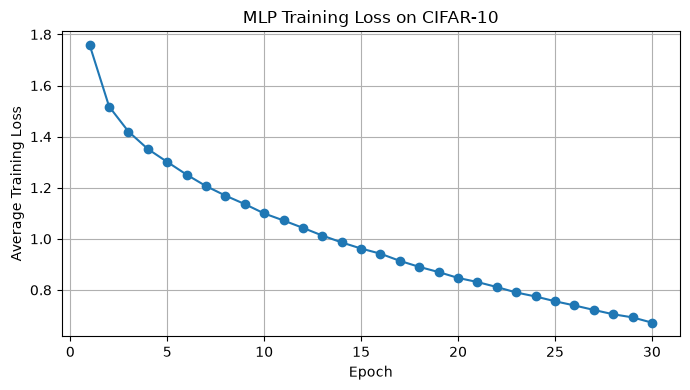

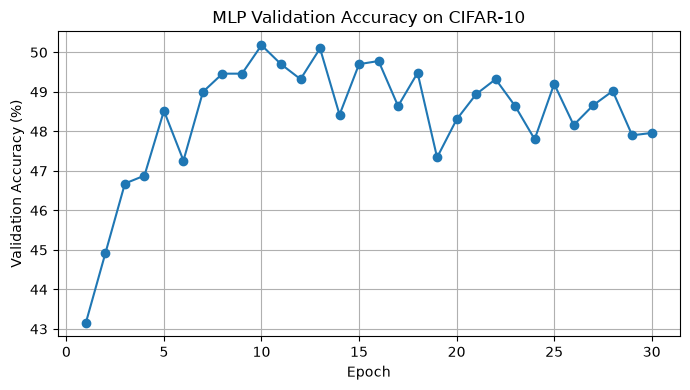

Final Training Loss: 0.6722
Final Validation Accuracy: 47.96%
Best Validation Accuracy: 50.18%


In [41]:

import matplotlib.pyplot as plt

epoch_numbers = range(1, len(train_losses) + 1)

# Figure 1: Training loss
plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("MLP Training Loss on CIFAR-10")
plt.grid(True)
plt.tight_layout()
plt.show()

# Figure 2: Validation accuracy
plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, val_accuracies, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("MLP Validation Accuracy on CIFAR-10")
plt.grid(True)
plt.tight_layout()
plt.show()

# Final results
print(f"Final Training Loss: {train_losses[-1]:.4f}")
print(f"Final Validation Accuracy: {val_accuracies[-1]:.2f}%")
print(f"Best Validation Accuracy: {max(val_accuracies):.2f}%")



**Figure 1: Training Loss vs. Epoch**

The training loss curve illustrates how the average cross-entropy loss changes during mini-batch SGD training. A decreasing training loss indicates that the optimizer is successfully minimizing the training objective.

**Figure 2: Validation Accuracy vs. Epoch**

The validation accuracy curve illustrates the model's classification performance on the 5,000 held-out validation images. It is used to evaluate generalization and identify whether additional training improves performance on unseen samples.



### 5. Experimental Results and Discussion

The manually implemented Multi-Layer Perceptron (MLP), with architecture **3072–128–64–10**, was trained on 45,000 flattened CIFAR-10 training images using mini-batch Stochastic Gradient Descent (SGD) for **30 epochs**. A batch size of 128 and a fixed learning rate of 0.05 were used.

#### Training Loss Analysis

The training loss curve (Figure 1) illustrates the optimization behavior of the MLP over 30 epochs.

The final average training loss was **0.6722**. The curve can be used to determine whether the manually implemented backpropagation and SGD updates successfully minimize the training objective.

#### Validation Accuracy Analysis

The validation accuracy curve (Figure 2) shows a rapid improvement during the initial training epochs, increasing from approximately 43% to 50%.

The highest validation accuracy was achieved around epoch 10. However, further training did not produce sustained improvements, and validation accuracy fluctuated during the remaining epochs.

The best and final validation accuracies were:

- **Best validation accuracy:** 50.18%
- **Best epoch:** 10
- **Final validation accuracy:** 47.96%

The observed validation fluctuations suggest that increasing the number of training epochs alone does not necessarily improve generalization. Possible contributing factors include optimization variability, the fixed learning rate, and overfitting.

#### Discussion

The MLP is able to learn useful classification patterns from flattened CIFAR-10 images. However, flattening removes the explicit spatial arrangement of image pixels, making it difficult for a fully connected network to exploit local image features compared with convolutional neural networks.

The experiment also demonstrates that improvements in the training objective do not always result in corresponding improvements in validation accuracy.

### 6. Conclusion

The manually implemented MLP was successfully trained using mini-batch SGD without relying on PyTorch autograd for gradient computation.

The experiment demonstrates that the custom forward propagation, backward propagation, and SGD parameter updates can be used to train a neural network for image classification.

Validation performance improved during the initial epochs but showed limited further improvement during extended training. Potential improvements include learning-rate scheduling, regularization, and early stopping.


**(d)** For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU. Explain.


### 1. Sigmoid Activation Function Implementation

The sigmoid activation function is implemented with explicit forward and backward passes. Its derivative is calculated manually without using PyTorch autograd.

The sigmoid derivative is bounded above by 0.25, which can cause gradients to become very small when propagated through many layers.


In [42]:

class Sigmoid:
    def forward(self, X):
        self.Y = torch.sigmoid(X)
        return self.Y

    def backward(self, dY):
        dX = dY * self.Y * (1 - self.Y)
        return dX



### 2. Construction of a 10-Layer MLP

A deep MLP containing 10 Linear layers is constructed with nine hidden layers of 128 neurons and an output layer of 10 neurons.

The network supports either Sigmoid or ReLU activation functions between consecutive Linear layers. The same manually implemented Linear and Softmax Cross-Entropy classes are reused.


In [43]:

class DeepMLP:
    def __init__(self, activation="relu"):

        # 3072 -> nine hidden layers (128) -> 10
        sizes = [3072] + [128] * 9 + [10]

        self.layers = []

        for i in range(len(sizes) - 1):

            # Add Linear layer
            self.layers.append(
                Linear(sizes[i], sizes[i + 1])
            )

            # Activation after every Linear layer
            # except the final output layer
            if i < len(sizes) - 2:
                if activation == "sigmoid":
                    self.layers.append(Sigmoid())
                elif activation == "relu":
                    self.layers.append(ReLU())
                else:
                    raise ValueError("Unknown activation")

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self, dY):
        for layer in reversed(self.layers):
            dY = layer.backward(dY)
        return dY



### 3. Per-Layer Gradient Norm Computation at Initialization

Two 10-layer MLPs are initialized with identical weights and biases, using Sigmoid and ReLU activations respectively. The existing He initialization from the custom Linear class is used for both networks to isolate the effect of the activation function.

A single mini-batch of normalized, flattened CIFAR-10 images is passed through each network. Manual backpropagation computes the weight gradients, and their Frobenius norms are recorded for all 10 Linear layers.

No parameter updates are performed, ensuring that the gradients are measured at initialization.


In [44]:

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Get one batch from the training dataset
images, labels = next(iter(train_loader))

X_batch = images.to(device).reshape(images.shape[0], -1)
y_batch = labels.to(device)

# Initialize both networks with identical parameters
torch.manual_seed(123)
model_sigmoid = DeepMLP(activation="sigmoid")

torch.manual_seed(123)
model_relu = DeepMLP(activation="relu")

# Move parameters to device
for net in [model_sigmoid, model_relu]:
    for layer in net.layers:
        if isinstance(layer, Linear):
            layer.W = layer.W.to(device)
            layer.b = layer.b.to(device)

# Verify identical initial weights
sig_linear = [l for l in model_sigmoid.layers
              if isinstance(l, Linear)]
relu_linear = [l for l in model_relu.layers
              if isinstance(l, Linear)]

assert all(
    torch.equal(a.W, b.W) and torch.equal(a.b, b.b)
    for a, b in zip(sig_linear, relu_linear)
)

def get_gradient_norms(net, X, labels):
    criterion = SoftmaxCrossEntropy()

    with torch.no_grad():

        # Forward pass
        logits = net.forward(X)
        loss = criterion.forward(logits, labels)

        # Manual backward pass
        dZ = criterion.backward()
        net.backward(dZ)

        # Frobenius norm of dW for each Linear layer
        norms = [
            torch.linalg.vector_norm(layer.dW).item()
            for layer in net.layers
            if isinstance(layer, Linear)
        ]

    return norms, loss.item()


sigmoid_norms, sigmoid_loss = get_gradient_norms(
    model_sigmoid, X_batch, y_batch
)

relu_norms, relu_loss = get_gradient_norms(
    model_relu, X_batch, y_batch
)

print("Sigmoid initial loss:", sigmoid_loss)
print("ReLU initial loss:", relu_loss)

print(f"\n{'Layer':<10} {'Sigmoid norm':>16} {'ReLU norm':>16}")
print("-" * 44)

for i, (s, r) in enumerate(zip(sigmoid_norms, relu_norms), 1):
    print(f"{i:<10} {s:>16.6e} {r:>16.6e}")


Sigmoid initial loss: 2.58624529838562
ReLU initial loss: 3.515939474105835

Layer          Sigmoid norm        ReLU norm
--------------------------------------------
1              1.897985e-04     9.039480e+00
2              1.685751e-04     2.801434e+00
3              5.733613e-04     3.594818e+00
4              1.858048e-03     4.192280e+00
5              6.393338e-03     4.652304e+00
6              1.901324e-02     4.813894e+00
7              5.713546e-02     4.403132e+00
8              1.800686e-01     4.346558e+00
9              5.832621e-01     4.891616e+00
10             1.828008e+00     6.025620e+00



### 4. Comparison of Per-Layer Gradient Norms: Sigmoid vs. ReLU

The Frobenius norms of the weight gradients are plotted against the Linear layer index for both activation functions.

A logarithmic vertical axis is used because gradient magnitudes can differ by several orders of magnitude. This visualization helps identify whether gradients diminish as they propagate toward the earlier layers.


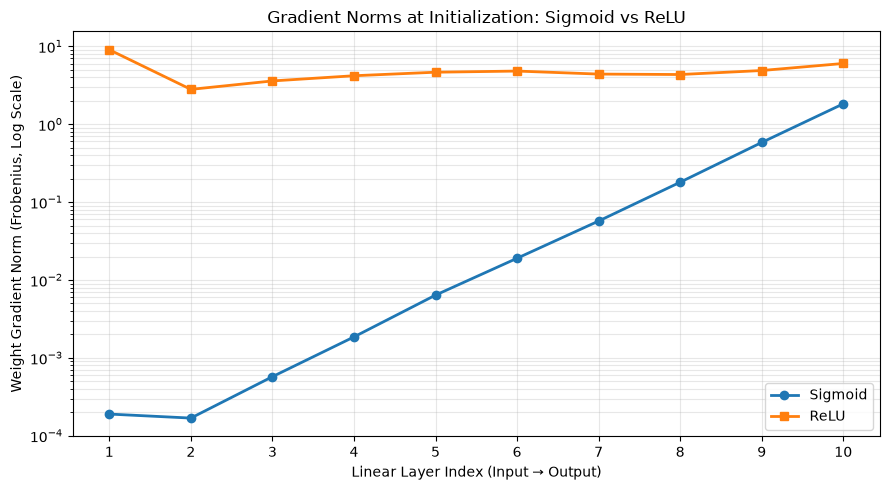

In [45]:

import matplotlib.pyplot as plt

layer_numbers = range(1, 11)

plt.figure(figsize=(9, 5))

plt.plot(
    layer_numbers,
    sigmoid_norms,
    marker="o",
    linewidth=2,
    label="Sigmoid"
)

plt.plot(
    layer_numbers,
    relu_norms,
    marker="s",
    linewidth=2,
    label="ReLU"
)

plt.yscale("log")

plt.xlabel("Linear Layer Index (Input → Output)")
plt.ylabel("Weight Gradient Norm (Frobenius, Log Scale)")
plt.title("Gradient Norms at Initialization: Sigmoid vs ReLU")

plt.xticks(list(layer_numbers))
plt.grid(True, which="both", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()



### 5. Experimental Results and Discussion

The gradient propagation behavior of a 10-layer MLP was investigated using Sigmoid and ReLU activation functions. Both networks were initialized with identical weights and biases, and gradients were calculated using manual backpropagation on the same CIFAR-10 mini-batch, without performing any parameter updates.

The Frobenius norm of the weight gradient was calculated for each Linear layer:

$$
G_l = \left\|\frac{\partial L}{\partial W_l}\right\|_F
$$

The resulting gradient norms were plotted against the layer index using a logarithmic scale.

#### Sigmoid Activation

The Sigmoid network exhibits a clear vanishing gradient problem. The gradient norm decreases from approximately **1.828 at Layer 10** to **0.000190 at Layer 1**, representing a reduction of approximately 9,600 times.

This occurs because the Sigmoid derivative is bounded by 0.25:

$$
\sigma'(z)=\sigma(z)(1-\sigma(z))\leq 0.25
$$

During backpropagation, repeated multiplication by small derivatives can significantly reduce the gradients reaching earlier layers. Consequently, these layers may learn very slowly during training.

#### ReLU Activation

In contrast, the ReLU network maintains substantially larger gradient norms, ranging approximately from **2.8 to 9.0** across the ten layers.

The ReLU derivative is:

$$
\operatorname{ReLU}'(z)=
\begin{cases}
1, & z>0\\
0, & z\leq0
\end{cases}
$$

Unlike Sigmoid, ReLU does not reduce gradients through its active neurons. This allows gradients to propagate more effectively through deep networks, although inactive neurons can still receive zero gradients.

#### Effect of Initialization

Both networks use the same He initialization and identical initial parameters to provide a controlled comparison of activation functions.

He initialization is primarily designed for ReLU-based networks. Therefore, the observed gradient behavior also depends on the initialization method, and the results should not be interpreted as universally applicable to every initialization strategy.

### 6. Conclusion

The experiment demonstrates the significant influence of activation functions on gradient propagation in deep neural networks.

The Sigmoid network exhibits severe vanishing gradients in its earlier layers, whereas the ReLU network maintains relatively stable and substantially larger gradient norms.

These findings illustrate why ReLU is generally preferred over Sigmoid in deep feedforward neural networks, particularly when avoiding vanishing gradients is important.


## Task 2: Optimizers

## Task 3: Regularization and residual connections

## Task 4: CNN design (optional)